## 📓 Notebook 04: Optuna Bayesian Optimization

**Skills practiced:** Writing an Optuna `objective(trial)`, `TPESampler`, `suggest_int` / `suggest_float`, optimization-history plots.

**Goal:** Search the same space with the same trial budget as random search, and add Optuna as the third row in your comparison table.

In [ ]:
import pandas as pd
import time
import os
import matplotlib.pyplot as plt
from optuna.visualization.matplotlib import (
    plot_optimization_history,
    plot_param_importances,
    plot_slice,
)

import optuna
import xgboost as xgb
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [27]:
x=pd.read_csv('../data/processed/x.csv')
y=pd.read_csv('../data/processed/y.csv').squeeze()

os.makedirs("../outputs/figures", exist_ok=True)

In [23]:
opt_start_time = time.time()
def objective(trial):
    model = xgb.XGBClassifier(
        max_depth=trial.suggest_int("max_depth", 3, 15),
        learning_rate=trial.suggest_float("learning_rate", 0.005, 0.4, log=True),
        n_estimators=trial.suggest_int("n_estimators", 50, 500),
        random_state=42,
    )
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    return cross_val_score(model, x, y, cv=cv, scoring="roc_auc").mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30)
opt_time = time.time() - opt_start_time

print("Best hyperparameters found: \n", study.best_params)
print("Best AUC score: ", study.best_value)
print(f"Optimization time: {opt_time:.2f} seconds")

[I 2026-11-18 17:22:34,350] A new study created in memory with name: no-name-c2ce729b-e646-40d0-af7e-7f14b4fd96c3
[I 2026-11-18 17:22:45,745] Trial 0 finished with value: 0.8048558541165953 and parameters: {'max_depth': 7, 'learning_rate': 0.3223033958565721, 'n_estimators': 380}. Best is trial 0 with value: 0.8048558541165953.
[I 2026-11-18 17:22:51,849] Trial 1 finished with value: 0.8259661673678934 and parameters: {'max_depth': 10, 'learning_rate': 0.009905753504069, 'n_estimators': 120}. Best is trial 1 with value: 0.8259661673678934.
[I 2026-11-18 17:22:55,913] Trial 2 finished with value: 0.8312370246458244 and parameters: {'max_depth': 3, 'learning_rate': 0.22252620134763365, 'n_estimators': 321}. Best is trial 2 with value: 0.8312370246458244.
[I 2026-11-18 17:23:11,577] Trial 3 finished with value: 0.8223969387343256 and parameters: {'max_depth': 12, 'learning_rate': 0.005471975564178365, 'n_estimators': 487}. Best is trial 2 with value: 0.8312370246458244.
[I 2026-11-18 17:2

Best hyperparameters found: 
 {'max_depth': 3, 'learning_rate': 0.012280016848961415, 'n_estimators': 453}
Best AUC score:  0.8468848782068636
Optimization time: 152.61 seconds


In [28]:
def save(fig, name):
    fig.savefig(f"../outputs/figures/{name}.png", dpi=200, bbox_inches="tight")

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15184\428978753.py:1: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(study)


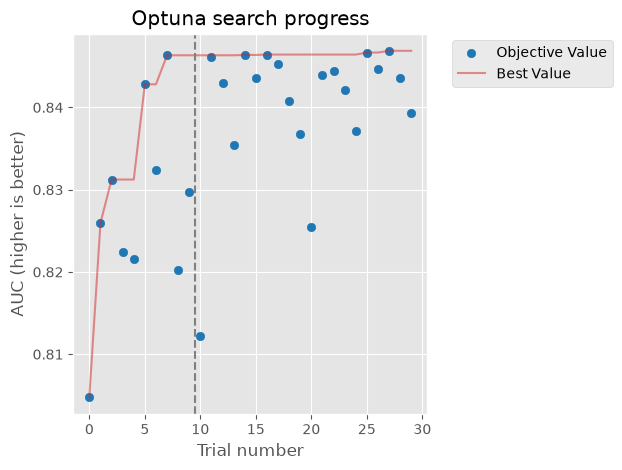

In [29]:
ax = plot_optimization_history(study)
ax.set_title("Optuna search progress")
ax.set_xlabel("Trial number")
ax.set_ylabel("AUC (higher is better)")
ax.axvline(9.5, color="gray", linestyle="--")
ax.figure.tight_layout()
save(ax.figure, "optuna_history")
plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15184\2952364590.py:1: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(study)


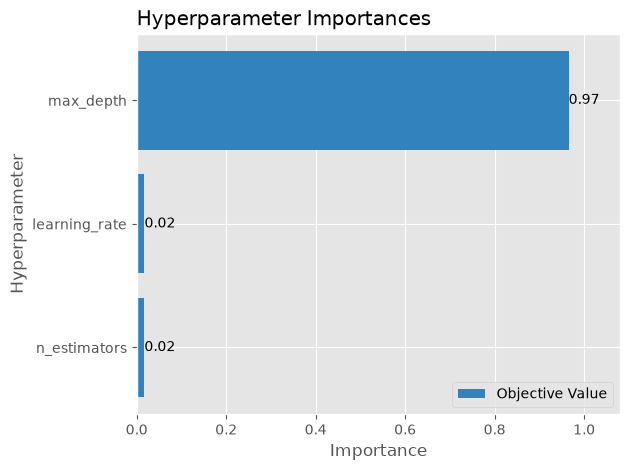

In [35]:
ax = plot_param_importances(study)
ax.set_xlabel("Importance")
ax.figure.tight_layout()
save(ax.figure, "optuna_importance")
plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15184\937253129.py:1: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  axes = plot_slice(study)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15184\937253129.py:4: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  axes[0].figure.tight_layout()


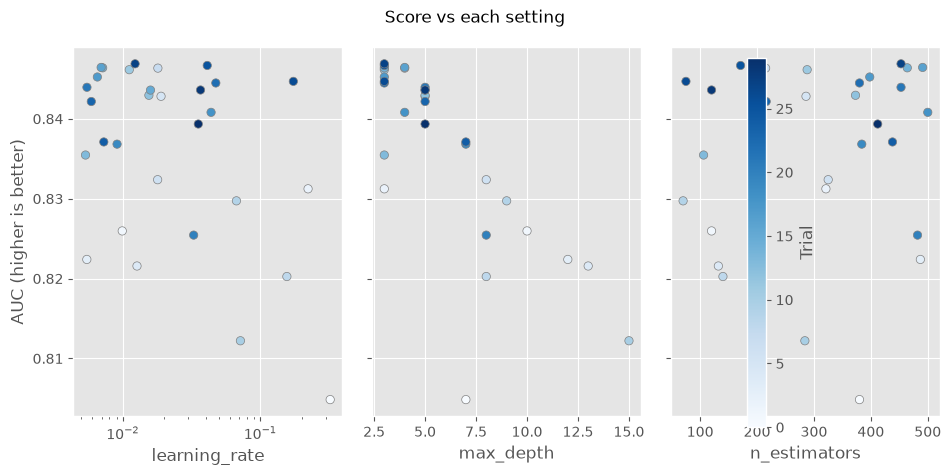

In [33]:
axes = plot_slice(study)
axes[0].set_ylabel("AUC (higher is better)")
axes[0].figure.suptitle("Score vs each setting")
axes[0].figure.tight_layout()
save(axes[0].figure, "optuna_slice")
plt.show()